In [1]:
import time
import torch
import numpy as np
from addict import Dict
import matplotlib.pyplot as plt

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

# 可视化
from utils.visualizer import plot_events_3d, plot_event_time2d, save_voxel_grid_video, plot_flow_field
from CMax import ContrastMaximizationLoss
from methods import inr_vg,inr_est,of_vg,of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities
# 评价指标
from utils.metrics import PIVmetric
from gaussian_flow import GaussianFlowConfig, run_gaussian_flow


CUDA acceleration: OK
Using device: cuda


317.989 8.128 326.117
torch.Size([1197394, 4])


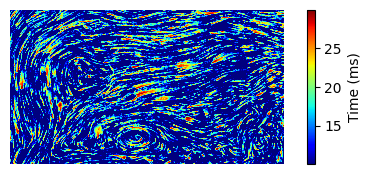

In [14]:
flow_index = 3
flow_names = ["rotation", "ebiv", "jet", "water"]

cases = [
    Dict(source_type="evk5", path="./data/real_old/rotation8.23.hdf5"), 
    Dict(source_type="real", path="./data/real_old/ebiv_wallflow4_dense.h5"),
    Dict(source_type="evk5", path="./data/real_old/starting_jet.hdf5"),
    Dict(source_type="evk5", path="./data/n10.hdf5")
    
]

event_loader = EventManager(**cases[flow_index])
evts, _ = event_loader.load()
print(evts[:, 2].max()-evts[:, 2].min(), evts[:, 2].min(), evts[:, 2].max())

evts1 = torch.tensor(evts[(evts[:, 2] > 10) & (evts[:, 2] < 30)]).to("cuda")
# evts2 = torch.tensor(evts[(evts[:, 2] > 10) & (evts[:, 2] < 50)]).to("cuda")

print(evts1.shape)

data = np.load("./data/real_old/rotation8.23_truth.npz")
vel_h = data["u"]
vel_w = data["v"]

flowgt = torch.stack([torch.tensor(vel_h), torch.tensor(vel_w)], dim=0).to("cuda")
plot_event_time2d(evts1, output_file=None)
# plot_flow_field(u_gt, v_gt)
# plot_flow_field(vel_h, vel_w, output_file=None, v_min = 0, v_max = 3, colorbar_flag=True, step=1, quiver_step=64, 
#                 scale=None, slFlag=False, figsize=(5, 3), cbar_ticks=None, cbar_tick_size=12)
torch.cuda.empty_cache()

[AutoLR] lr_jacobian = 0.01 (manual)
开始训练 | 初始高斯数: 100
Iter 0000 | total=-6.371739 | data=-6.869130 | div=0.009948 | smooth=0.023379 | J_grad=0.71529 | N=100
  [DensityCtrl] valid_blocks=3600  localvar_mean=0.0135  cov_mean=0.0169  curv_mean=0.1149
  [Clone] block_candidates=453  selected=50  copied=50  random=0  radius=140.0
gaussian_candidates=3  selected=3  res_support_mean=0.0214  curv_support_mean=0.4450
  [Prune] opacity=0  geometry=6  nonfinite=0  total=6
  [{'prune', 'split', 'clone'}] Clone:50  Split:3  Prune:6  -> N=147
Iter 0050 | total=-9.958771 | data=-10.484194 | div=0.010508 | smooth=0.021754 | J_grad=29.17128 | N=147
  [DensityCtrl] valid_blocks=3600  localvar_mean=0.0130  cov_mean=0.1941  curv_mean=0.1912
  [Clone] block_candidates=386  selected=50  copied=50  random=0  radius=140.0
gaussian_candidates=1  selected=1  res_support_mean=0.0203  curv_support_mean=0.4291
  [Prune] opacity=46  geometry=11  nonfinite=0  total=57
  [{'prune', 'split', 'clone'}] Clone:50  Split

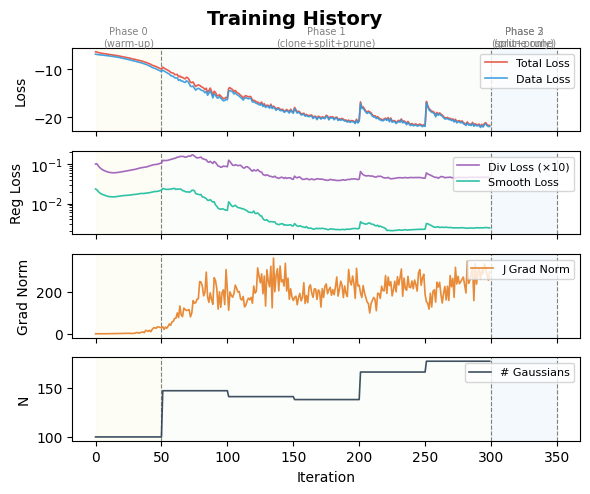

验证推理中（训练分辨率 720×1280 → 输出分辨率 720×1280）...
验证推理完成
运行时间: 5.602308 秒


In [32]:
start = time.time()
cfg = GaussianFlowConfig(H=720, W = 1280, init_n=100, w_div=50, verbose=True, tile_size=80, 
                         w_smooth = 0, cmax_sigma= 0.6, cmax_kernel_size = 5, lr_j=0.01, 
                         enable_jacobian = True, iterations=300, residual_block_size=16, log_scale_min=np.log(3), phase=[50, 300, 350])
results = run_gaussian_flow(events=evts1, cfg=cfg, flowgt=None)

end = time.time()     # 记录结束时间
print(f"运行时间: {end - start:.6f} 秒")
torch.cuda.empty_cache()

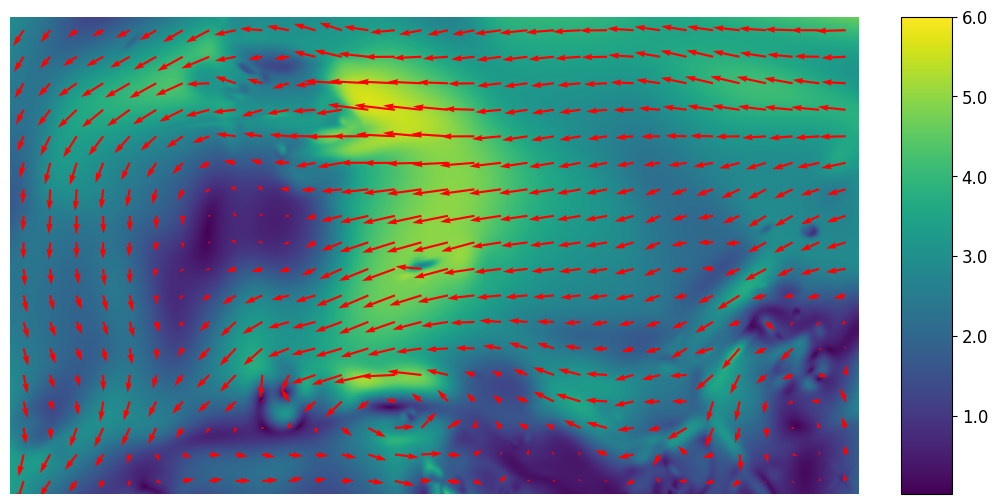

In [33]:
plot_flow_field(results.flow[0], results.flow[1], output_file=None, v_max = 6, 
                colorbar_flag=True, step=1, quiver_step=40, scale=None, slFlag=False, figsize=(10, 6))

In [5]:
# estimators = [ilk_vg, of_vg, inr_est, inr_vg]
# method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG"]

estimators = [inr_vg]
method_names = ["INR_VG"]

def test(events, H=256, W=256):
    for i, m in enumerate(estimators):
        v_h, v_w, div, vor = m(events, H=H, W=W)
        plot_flow_field(v_h, v_w, None, None, output_file=f"./output/EXP3/{method_names[i]}-{flow_names[flow_index]}.svg", magFlag=True, slFlag=False, colorbar_flag=True, step=1, quiver_step=80, 
                            v_min=0, v_max=4, scale=None, figsize=(5, 3), cbar_ticks=None, cbar_tick_size=12)
        torch.cuda.empty_cache()

    return 

Figure saved to ./output/EXP3/INR_VG-ebiv.svg


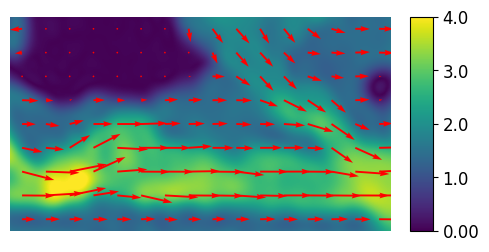

In [6]:
test(evts1, H=720, W=1280)